# Quantised ResNet-18: is it worth switching?

Both apps spend about 3 s per clip in ResNet-18 and about 11 s in the colour detector; the TCN and GRU take about 0.1 s ([timings](../docs/gru-predict.md#time-per-clip-cpu)). This notebook converts the frozen ResNet-18 to int8 and measures four things:

1. how much faster and smaller the encoder gets;
2. how close the int8 features are to the float ones;
3. how much of a clip's total time that saves;
4. whether the saved TCN and GRU still give the same predictions.

**Nothing in the apps changes.** The int8 encoder is swapped in only inside this notebook. The same steps run from the command line with `scripts/quantised_resnet_demo.py`.

## How the int8 encoder is made

Post-training static quantisation: PyTorch watches the float ResNet-18 run on real radar frames (calibration), picks an int8 scale for every layer, then converts the weights and activations to int8. Calibration uses 8 **training** clips; the test clips are never used to build it. No retraining is involved: the TCN and GRU checkpoints are untouched.

Needs the 2026-11-16 training clips under `data/processed/datasets/` and the three demo clips in `deploy/streamlit/samples/`.

In [1]:
# @title Setup
import contextlib
import io
import os
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'stratscout').is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / 'scripts')]
warnings.filterwarnings('ignore')  # torch.ao.quantization prints a deprecation notice

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from quantised_resnet_demo import SAMPLES, as_encode, quantise, seconds, size_mb
from stratscout import clip_data, gru_predict
from stratscout.context import RunContext
from stratscout.tactic_model import build_baseline

%matplotlib inline
FLOAT, INT8 = '#257de0', '#f47230'  # one colour per encoder throughout
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e6', 'axes.axisbelow': True,
                     'font.size': 10})
torch.manual_seed(0)
print('PyTorch', torch.__version__, '| quantised engines:', torch.backends.quantized.supported_engines)
print('Demo clips:', [p.name for p in SAMPLES])

PyTorch 2.14.1+cpu | quantised engines: ['onednn']
Demo clips: ['navi-falcons-mirage-cologne-major.jx.s029.mp4', 'vitality-falcons-mirage-esl-pro-league-season-24.jx.s001.mp4', 'vitality-falcons-mirage-esl-pro-league-season-24.jx.s006.mp4']


In [2]:
# @title Build both encoders
float_model = build_baseline(context=RunContext(device='cpu')).encoder.eval()
int8_model = quantise(build_baseline(context=RunContext(device='cpu')).encoder.eval())
float_encode, int8_encode = as_encode(float_model), as_encode(int8_model)
print('Built the float32 and int8 ResNet-18 encoders.')

Built the float32 and int8 ResNet-18 encoders.


## 1. Encoder speed and size

One batch of 64 frames (224 × 224), averaged over 5 runs after a warm-up.

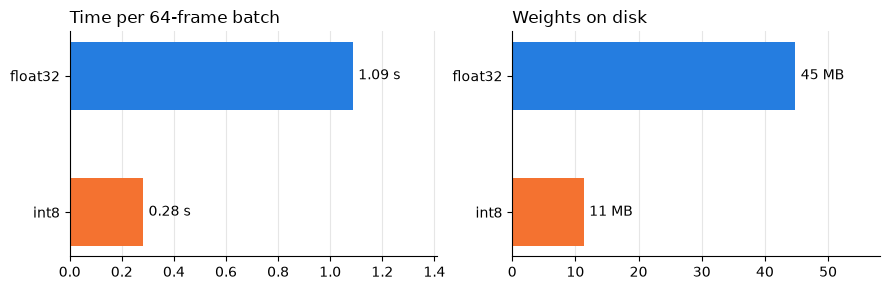

int8 is **3.9× faster** and **4.0× smaller**.

In [3]:
# @title Speed and size
batch = torch.randn(64, 3, 224, 224)
speed = {'float32': seconds(float_encode, batch, 5), 'int8': seconds(int8_encode, batch, 5)}
size = {'float32': size_mb(float_model), 'int8': size_mb(int8_model)}

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, values, title, unit in ((axes[0], speed, 'Time per 64-frame batch', 's'),
                                (axes[1], size, 'Weights on disk', 'MB')):
    bars = ax.barh(list(values), list(values.values()), color=[FLOAT, INT8], height=0.5)
    ax.bar_label(bars, [f'{v:.2f} {unit}' if unit == 's' else f'{v:.0f} {unit}' for v in values.values()], padding=4)
    ax.set_title(title, loc='left')
    ax.invert_yaxis()
    ax.set_xlim(0, max(values.values()) * 1.3)
    ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()
display(Markdown(f"int8 is **{speed['float32'] / speed['int8']:.1f}× faster** and "
                 f"**{size['float32'] / size['int8']:.1f}× smaller**."))

## 2. How close are the features?

Every second frame of each demo clip goes through both encoders, as the apps do. Cosine similarity compares each frame's two 512-number feature vectors: 1 means identical direction.

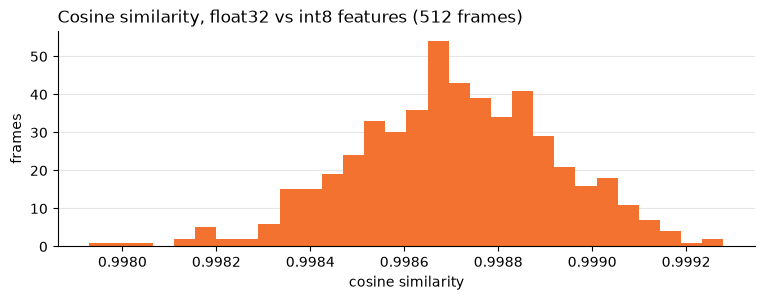

median 0.9987, lowest 0.9979


In [4]:
# @title Feature similarity on real frames
def clip_rows(path, encode):
    n = int(cv2.VideoCapture(str(path)).get(cv2.CAP_PROP_FRAME_COUNT))
    start = time.perf_counter()
    rows, _ = clip_data.resnet_rows(path, np.arange(0, n, 2), encode)
    return rows.astype(np.float32), time.perf_counter() - start

similarity, resnet_time = [], []
for path in SAMPLES:
    a, t_a = clip_rows(path, float_encode)
    b, t_b = clip_rows(path, int8_encode)
    cos = (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
    similarity.append(cos)
    resnet_time.append({'clip': path.stem.split('.')[-1], 'float32': t_a, 'int8': t_b})

allcos = np.concatenate(similarity)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.hist(allcos, bins=30, color=INT8)
ax.set_title(f'Cosine similarity, float32 vs int8 features ({len(allcos)} frames)', loc='left')
ax.set_xlabel('cosine similarity')
ax.set_ylabel('frames')
ax.grid(axis='x', visible=False)
plt.show()
print(f'median {np.median(allcos):.4f}, lowest {allcos.min():.4f}')

## 3. Time saved per clip

ResNet time per clip is measured above. The detector and the models are the same for both encoders, so the detector's share comes from the [measured timings](../docs/gru-predict.md#time-per-clip-cpu) (about 0.4 s per second of clip).

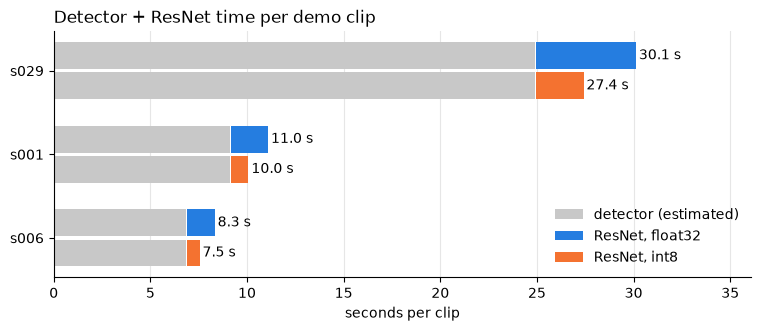

,float32,int8,clip length (s),"detector, estimated (s)"
clip,,,,
s029,5.15,2.44,62.3,24.92
s001,1.92,0.91,22.8,9.12
s006,1.44,0.66,17.1,6.84


ResNet alone: **2.1× faster**. Detector + ResNet: **9% less time** per clip.

In [5]:
# @title ResNet time vs the whole clip
rt = pd.DataFrame(resnet_time).set_index('clip')
rt['clip length (s)'] = [int(cv2.VideoCapture(str(p)).get(cv2.CAP_PROP_FRAME_COUNT)) / 10 for p in SAMPLES]
rt['detector, estimated (s)'] = 0.4 * rt['clip length (s)']

fig, ax = plt.subplots(figsize=(9, 3.2))
y = np.arange(len(rt))
for i, (name, colour) in enumerate((('float32', FLOAT), ('int8', INT8))):
    pos = y + (i - 0.5) * 0.36
    ax.barh(pos, rt['detector, estimated (s)'], height=0.32, color='#c8c8c8',
            label='detector (estimated)' if i == 0 else None)
    ax.barh(pos, rt[name], left=rt['detector, estimated (s)'] + 0.05, height=0.32, color=colour,
            label=f'ResNet, {name}')
    for p, d, r in zip(pos, rt['detector, estimated (s)'], rt[name]):
        ax.text(d + r + 0.2, p, f'{d + r:.1f} s', va='center')
ax.set_yticks(y, rt.index)
ax.invert_yaxis()
ax.set_xlabel('seconds per clip')
ax.set_title('Detector + ResNet time per demo clip', loc='left')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=False)
ax.set_xlim(0, (rt['detector, estimated (s)'] + rt['float32']).max() * 1.2)
plt.show()
total_f = (rt['detector, estimated (s)'] + rt['float32']).sum()
total_q = (rt['detector, estimated (s)'] + rt['int8']).sum()
display(rt.round(2))
display(Markdown(f'ResNet alone: **{rt.float32.sum() / rt.int8.sum():.1f}× faster**. '
                 f'Detector + ResNet: **{100 * (1 - total_q / total_f):.0f}% less time** per clip.'))

## 4. Do the predictions change?

The saved TCN and GRU ensembles (three seeds each) classify the three demo clips twice: with float32 ResNet features, then with int8 ones. These are held-out test clips; nothing is fitted to them.

In [6]:
# @title Predictions with each encoder
def predict():
    gru_predict.clear_model_cache()
    with contextlib.redirect_stdout(io.StringIO()):  # hide per-clip progress lines
        results = gru_predict.predict_clips(SAMPLES, models=('tcn', 'gru'), log=lambda *a: None)
    return {r['clip'].split('.')[-1]: r['predictions'] for r in results}

original_encoder = clip_data.resnet_encoder
before = predict()
clip_data.resnet_encoder = lambda device='cpu': int8_encode
try:
    after = predict()
finally:
    clip_data.resnet_encoder = original_encoder

rows = []
for clip in before:
    for model in ('tcn', 'gru'):
        p, q = before[clip][model], after[clip][model]
        rows.append({'clip': clip, 'model': model.upper(), 'float32': p['tactic'], 'int8': q['tactic'],
                     'same class': p['tactic'] == q['tactic'],
                     'confidence float32': p['confidence'], 'confidence int8': q['confidence'],
                     'change': q['confidence'] - p['confidence']})
pred = pd.DataFrame(rows)
display(pred.round(3))

,clip,model,float32,int8,same class,confidence float32,confidence int8,change
0,s029,TCN,A_SPLIT,A_SPLIT,True,0.856,0.864,0.008
1,s029,GRU,A_SPLIT,A_SPLIT,True,0.725,0.726,0.001
2,s001,TCN,A_DIRECT,A_DIRECT,True,0.834,0.842,0.008
3,s001,GRU,A_DIRECT,A_DIRECT,True,0.878,0.821,-0.057
4,s006,TCN,B_SPLIT,B_SPLIT,True,0.970,0.964,-0.006
5,s006,GRU,B_SPLIT,B_SPLIT,True,0.984,0.982,-0.002


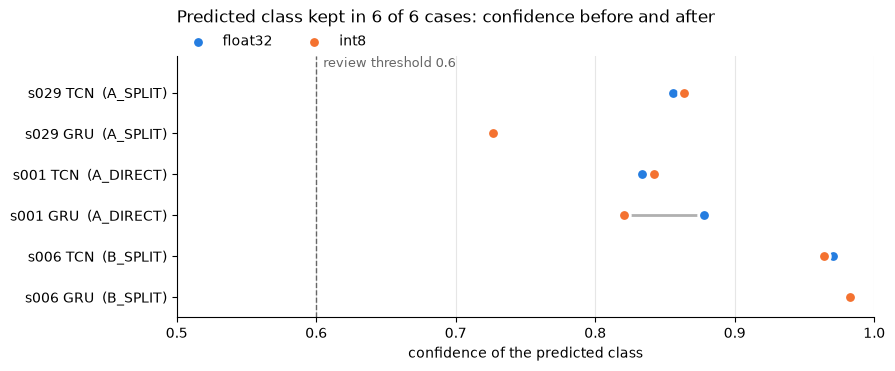

6 of 6 predictions keep their class; largest confidence change 0.057.


In [7]:
# @title Confidence before and after
fig, ax = plt.subplots(figsize=(9, 3.4))
labels = [f"{r.clip} {r.model}" for r in pred.itertuples()]
y = np.arange(len(pred))
ax.hlines(y, pred['confidence float32'], pred['confidence int8'], color='#b0b0b0', lw=2)
ax.scatter(pred['confidence float32'], y, s=70, color=FLOAT, zorder=3, label='float32', edgecolor='white', linewidth=2)
ax.scatter(pred['confidence int8'], y, s=70, color=INT8, zorder=3, label='int8', edgecolor='white', linewidth=2)
ax.set_yticks(y, [f'{l}  ({c})' for l, c in zip(labels, pred['float32'])])
ax.invert_yaxis()
ax.axvline(0.6, color='#666666', lw=1, ls='--')
ax.text(0.605, -0.55, 'review threshold 0.6', color='#666666', fontsize=9, va='bottom')
ax.set_xlim(0.5, 1.0)
ax.set_ylim(len(pred) - 0.5, -0.9)
ax.set_xlabel('confidence of the predicted class')
kept = pred['same class'].sum()
ax.set_title(f'Predicted class kept in {kept} of {len(pred)} cases: confidence before and after',
             loc='left', pad=24)
ax.grid(axis='y', visible=False)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), frameon=False, ncol=2, borderaxespad=0.1)
plt.show()
print(f"{pred['same class'].sum()} of {len(pred)} predictions keep their class; "
      f"largest confidence change {pred['change'].abs().max():.3f}.")

## Decision

Figures from the run saved in this notebook, on the development laptop's CPU.

| | Result |
|---|---|
| ResNet-18 on a batch of frames | about 4× faster |
| ResNet-18 per clip, including reading and resizing frames | about 2× faster |
| ResNet-18 size | 45 MB → 11 MB |
| Detector + ResNet time per clip | about 9% less, because the colour detector still dominates |
| Predictions | same class on all 3 demo clips for both models; confidence moves slightly |

**The apps keep the float32 ResNet-18.** The saving is small for a user, the reported TCN and GRU results were produced with float32 features, and three clips are too few to show that the predictions never change. Switching would need the same check on all 45 test clips, an int8 model file built once and committed (the cloud app has no training clips to calibrate on), and a move to `torchao`, since the `torch.ao.quantization` API used here is deprecated.

The larger target is the colour detector (about 11 s per clip), but running it on fewer frames would change the models' input and need the cross-validation rerun.